# Signal chain: from samples to RINEX

This notebook follows a GPS L1 C/A recording through the receiver's signal chain: what the
samples look like, how acquisition finds each satellite, how the tracking loops settle on
it, how the navigation message yields time and orbits, and how the tracked channels become
pseudoranges, carrier phases and Dopplers written to a RINEX file.

It runs on a 30 s recording made in Japan on 2021-12-26 when the environment variable
`PYRX_CAPTURES` points at the recordings directory (see `../README.md`), and otherwise on a
synthetic recording of four satellites generated here. The committed outputs are from the
recording.

The fundamentals behind each section:
[From antenna to samples](../../docs/fundamentals/03-antenna-to-samples.md),
[Finding a satellite](../../docs/fundamentals/04-acquisition.md),
[Staying locked](../../docs/fundamentals/05-tracking.md),
[Reading the message](../../docs/fundamentals/06-navigation-message.md),
[The measurements](../../docs/fundamentals/07-measurements.md).

In [1]:
import dataclasses
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import welch
from support import (
    data_source,
    figure,
    read_ctrk_log,
    read_trk_log,
    scratch_dir,
    synthetic_recording,
)

from pyrx.acquisition import DETECT_THRESHOLD, acquire_l1ca
from pyrx.codes import CA_CHIP_RATE
from pyrx.navdecode import decode_lnav
from pyrx.observables import code_starts, make_observables, transmit_times
from pyrx.orbits import select_ephemeris
from pyrx.plots import BAR, BAR_DETECTED, LINES, MUTED
from pyrx.rinex import read_rinex_nav, write_rinex_nav, write_rinex_obs
from pyrx.samples import read_samples
from pyrx.synth import ephemeris as synthetic_ephemeris
from pyrx.tracking import T_FLL_PULLIN, track_channels

out = scratch_dir("01-signal-chain")
src = data_source()
if src is not None:
    path, fs, f_if, iq = src.recording, src.fs, src.f_if, src.iq
else:
    path, fs, f_if, iq, _ = synthetic_recording(out)
print(f"{path.name}: {fs / 1e6:g} MHz {'I/Q' if iq else 'real'} samples, IF {f_if / 1e6:g} MHz")

running on the recordings under /home/aklofas/Projects/purple-gnss/captures
L1_20211226_082401_24MHz_I.bin: 24 MHz real samples, IF 6 MHz


## 1. The recording

The front-end quantises the antenna signal to a few bits: this file holds one byte per
sample. The histogram shows how few levels there are; the time slice shows that nothing
is visible by eye, because every satellite's signal lies some 20 dB below the noise. The
spectrum shows the shape of the front-end's passband around the intermediate frequency (IF)
the signal was mixed down to.

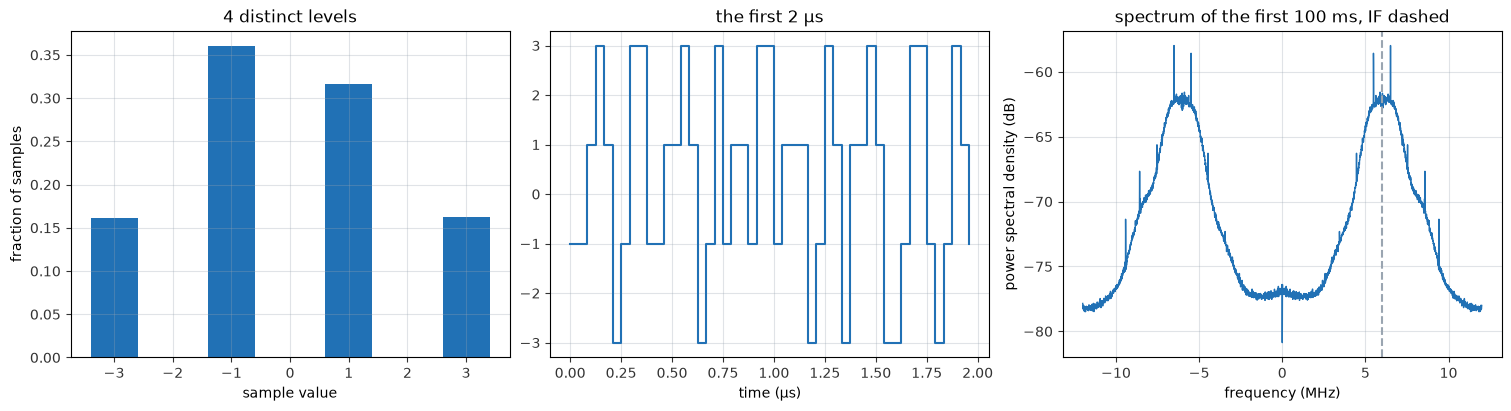

In [2]:
samples_per_byte = 2 if iq else 1
raw = np.fromfile(path, dtype=np.int8, count=int(fs * 0.1) * samples_per_byte)
x = read_samples(path, fs, iq, 0.0, 0.1)
levels, counts = np.unique(raw, return_counts=True)
n_slice = max(int(2e-6 * fs), 16)
f, pxx = welch(x, fs, nperseg=4096, return_onesided=False)
f, pxx = np.fft.fftshift(f), np.fft.fftshift(pxx)

fig, (ax_h, ax_t, ax_s) = figure(1, 3, figsize=(15, 4))
ax_h.bar(levels, counts / counts.sum(), color=BAR_DETECTED, width=0.8)
ax_h.set_xlabel("sample value")
ax_h.set_ylabel("fraction of samples")
ax_h.set_title(f"{len(levels)} distinct levels")
t_us = np.arange(n_slice) / fs * 1e6
ax_t.step(t_us, x[:n_slice].real, where="post", color=LINES[0], label="I")
if iq:
    ax_t.step(t_us, x[:n_slice].imag, where="post", color=LINES[1], label="Q")
    ax_t.legend()
ax_t.set_xlabel("time (µs)")
ax_t.set_title("the first 2 µs")
ax_s.plot(f / 1e6, 10 * np.log10(pxx), color=LINES[0], linewidth=1)
ax_s.axvline(f_if / 1e6, color=MUTED, linestyle="--")
ax_s.set_xlabel("frequency (MHz)")
ax_s.set_ylabel("power spectral density (dB)")
ax_s.set_title("spectrum of the first 100 ms, IF dashed")
plt.show()

## 2. Acquisition

Each satellite transmits its own 1 ms spreading code. Acquisition correlates 10 ms of
samples with a local copy of each code at every code offset and at a grid of Doppler
shifts, and looks for a peak. The bar chart gives the carrier-to-noise density (C/N0)
of the best cell per PRN; a satellite is declared present above the dashed threshold.
The grid below it is the search space for the strongest satellite, with the Doppler cut
through its peak.

detected: PRN 4 (42.6 dB-Hz, +463 Hz), PRN 16 (46.1 dB-Hz, +696 Hz), PRN 18 (41.2 dB-Hz, +476 Hz), PRN 26 (48.7 dB-Hz, -1020 Hz), PRN 27 (46.3 dB-Hz, +2528 Hz), PRN 29 (39.0 dB-Hz, -3861 Hz), PRN 31 (47.4 dB-Hz, -2441 Hz)


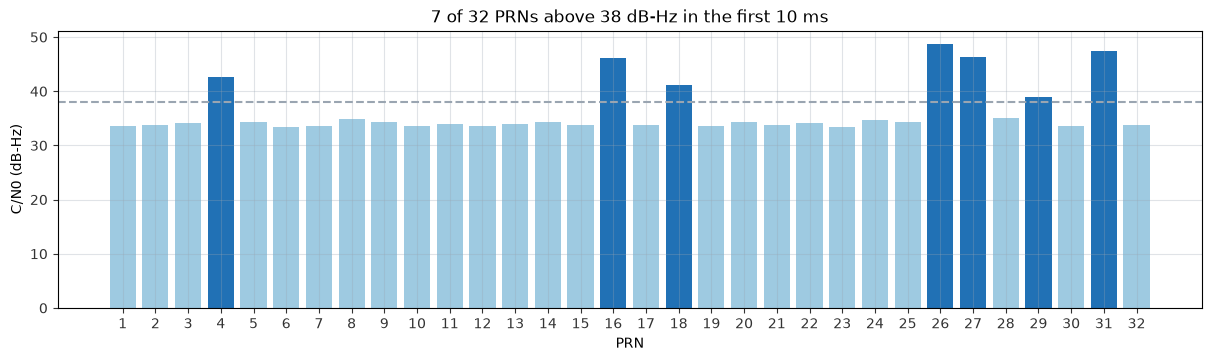

In [3]:
head = read_samples(path, fs, iq, 0.0, 0.010)
results = [acquire_l1ca(head, fs, f_if, prn) for prn in range(1, 33)]
detected = [r for r in results if r.detected]
best = max(results, key=lambda r: r.cn0)
print("detected:", ", ".join(f"PRN {r.prn} ({r.cn0:.1f} dB-Hz, {r.doppler:+.0f} Hz)" for r in detected))

fig, ax = figure(figsize=(12, 3.5))
ax.bar([r.prn for r in results], [r.cn0 for r in results],
       color=[BAR_DETECTED if r.detected else BAR for r in results], width=0.8)
ax.axhline(DETECT_THRESHOLD, color=MUTED, linestyle="--")
ax.set_xlabel("PRN")
ax.set_ylabel("C/N0 (dB-Hz)")
ax.set_title(f"{len(detected)} of 32 PRNs above {DETECT_THRESHOLD:.0f} dB-Hz in the first 10 ms")
ax.set_xticks(range(1, 33))
plt.show()

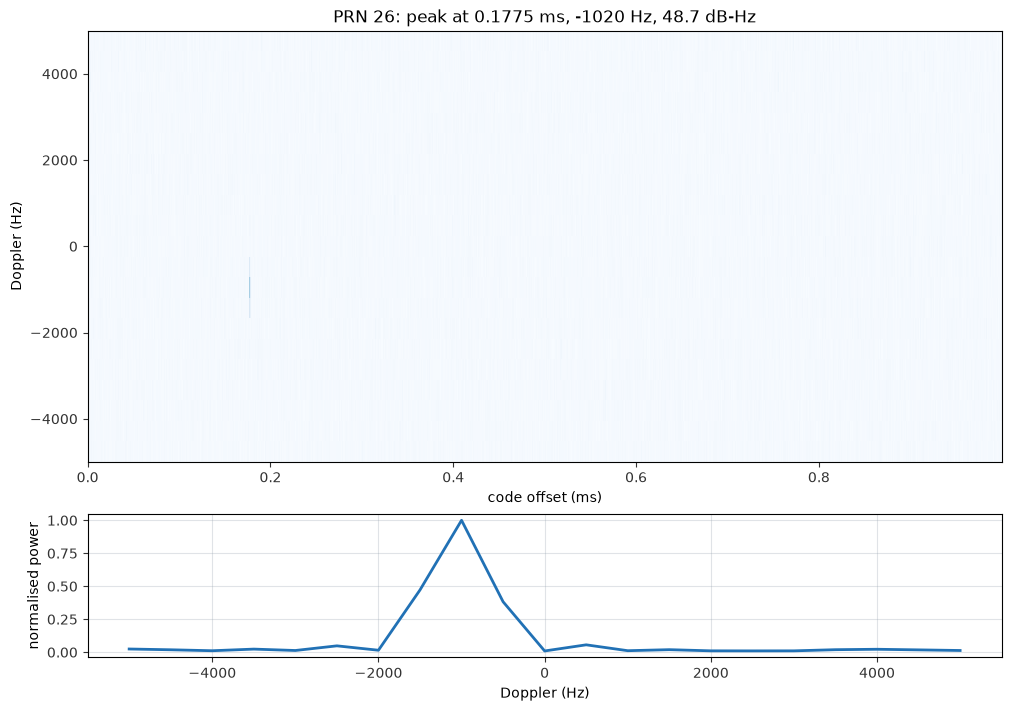

In [4]:
offsets_ms = np.arange(best.grid.shape[1]) / fs * 1e3
col = round(best.code_offset * fs)
fig, (ax_g, ax_c) = figure(2, 1, figsize=(10, 7), gridspec_kw={"height_ratios": [3, 1]})
ax_g.imshow(best.grid, aspect="auto", origin="lower", cmap="Blues", interpolation="nearest",
            extent=(offsets_ms[0], offsets_ms[-1], best.dopplers[0], best.dopplers[-1]))
ax_g.grid(False)
ax_g.set_xlabel("code offset (ms)")
ax_g.set_ylabel("Doppler (Hz)")
ax_g.set_title(f"PRN {best.prn}: peak at {best.code_offset * 1e3:.4f} ms, "
               f"{best.doppler:+.0f} Hz, {best.cn0:.1f} dB-Hz")
ax_c.plot(best.dopplers, best.grid[:, col], color=BAR_DETECTED, linewidth=2)
ax_c.set_xlabel("Doppler (Hz)")
ax_c.set_ylabel("normalised power")
plt.show()

## 3. Tracking

A tracking channel keeps a local code and carrier aligned with the incoming signal, one
code period (1 ms) at a time. For the first second a frequency-locked loop (FLL) pulls the
carrier frequency in; after that a Costas phase-locked loop (PLL) holds the phase, and a
delay-locked loop (DLL) keeps the code aligned from the early-minus-late power every 10 ms.

Once the PLL has locked, the prompt correlation collapses onto the real axis and its sign
flips every 20 ms with the navigation data bits. The discriminator traces show the loops
settling: the carrier error drops to a fraction of a cycle after the FLL hands over, the
code error to a fraction of a chip.

tracked 6 channels in 29 s


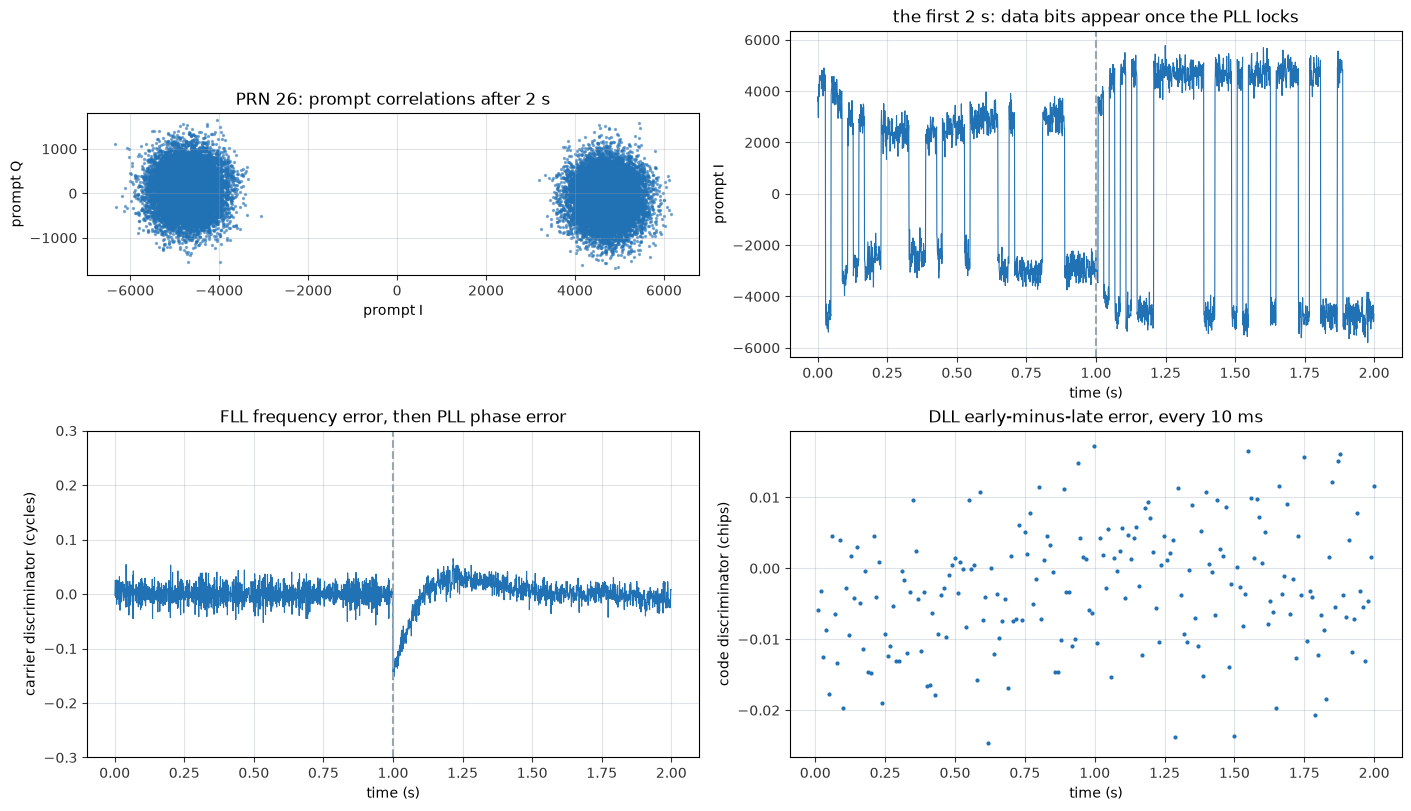

In [5]:
seeds = [(r.prn, r.code_offset, r.doppler, r.cn0)
         for r in sorted(detected, key=lambda r: -r.cn0)[:6]]
t0 = time.perf_counter()
tracks = track_channels(path, fs, iq, f_if, seeds)
print(f"tracked {len(tracks)} channels in {time.perf_counter() - t0:.0f} s")
track = tracks[0]
prompt = track.corr[:, 0]
rel_t = track.t - track.t[0]
first = rel_t < 2.0

fig, axes = figure(2, 2, figsize=(14, 8))
ax = axes[0, 0]
ax.scatter(prompt[~first].real, prompt[~first].imag, s=2, color=LINES[0], alpha=0.5)
ax.set_aspect("equal")
ax.set_xlabel("prompt I")
ax.set_ylabel("prompt Q")
ax.set_title(f"PRN {track.prn}: prompt correlations after 2 s")
ax = axes[0, 1]
ax.plot(rel_t[first], prompt[first].real, color=LINES[0], linewidth=0.8)
ax.axvline(T_FLL_PULLIN, color=MUTED, linestyle="--")
ax.set_xlabel("time (s)")
ax.set_ylabel("prompt I")
ax.set_title("the first 2 s: data bits appear once the PLL locks")
ax = axes[1, 0]
ax.plot(rel_t[first], track.carrier_error[first], color=LINES[0], linewidth=0.8)
ax.axvline(T_FLL_PULLIN, color=MUTED, linestyle="--")
ax.set_ylim(-0.3, 0.3)
ax.set_xlabel("time (s)")
ax.set_ylabel("carrier discriminator (cycles)")
ax.set_title("FLL frequency error, then PLL phase error")
ax = axes[1, 1]
upd = first & np.isfinite(track.code_error)
ax.plot(rel_t[upd], track.code_error[upd] * CA_CHIP_RATE, ".", color=LINES[0], markersize=4)
ax.set_xlabel("time (s)")
ax.set_ylabel("code discriminator (chips)")
ax.set_title("DLL early-minus-late error, every 10 ms")
plt.show()

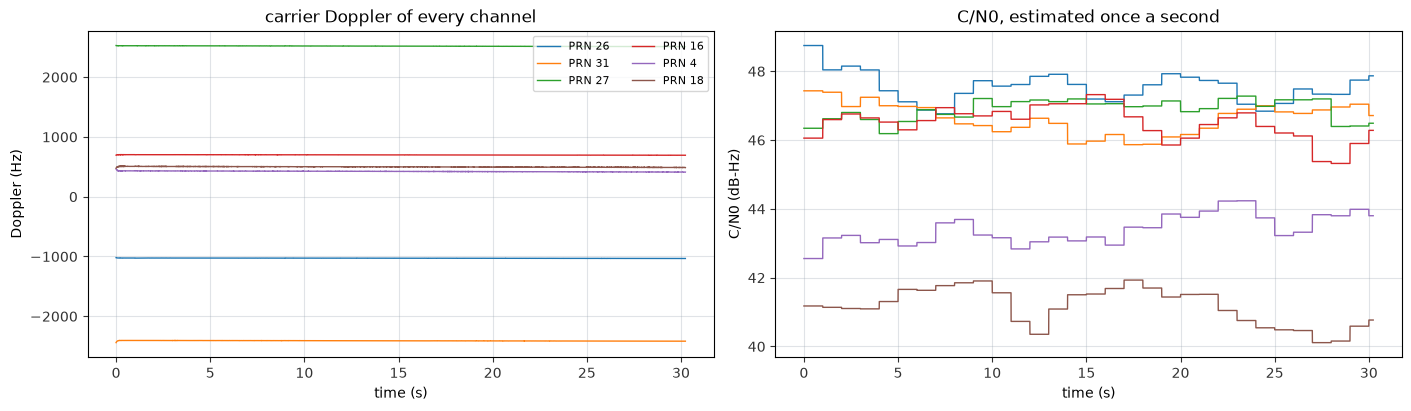

In [6]:
fig, (ax_d, ax_c) = figure(1, 2, figsize=(14, 4))
for tr in tracks:
    ax_d.plot(tr.t - tr.t[0], tr.doppler, linewidth=1, label=f"PRN {tr.prn}")
    ax_c.plot(tr.t - tr.t[0], tr.cn0, linewidth=1, label=f"PRN {tr.prn}")
ax_d.set_xlabel("time (s)")
ax_d.set_ylabel("Doppler (Hz)")
ax_d.set_title("carrier Doppler of every channel")
ax_d.legend(ncol=2, fontsize=8)
ax_c.set_xlabel("time (s)")
ax_c.set_ylabel("C/N0 (dB-Hz)")
ax_c.set_title("C/N0, estimated once a second")
plt.show()

## 4. The navigation message

The bit signs of the prompt correlation carry a 50 bit/s message. Bit sync finds the 20 ms
bit edges, frame sync finds the 8-bit preamble that opens each 300-bit subframe and checks
the parity of every word. Subframe 1 carries the week number and clock terms, subframes 2
and 3 the orbit (the ephemeris); the handover word in every subframe gives the time of
week, which is what turns a code phase into a transmit time.

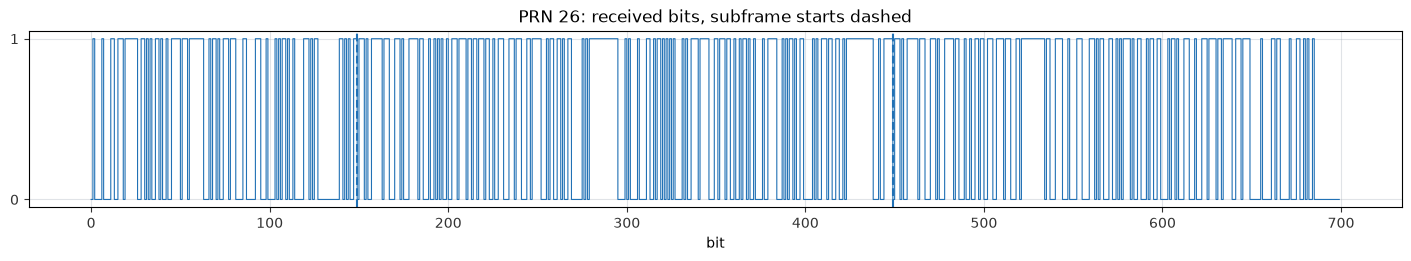

,PRN,subframe,TOW (s),week (mod 1024),first-bit epoch
0,26,5,30264,NaN,4488
1,26,1,30270,142.0,10488
2,26,2,30276,NaN,16488
3,26,3,30282,NaN,22488
4,31,5,30264,NaN,4491
5,31,1,30270,142.0,10491
6,31,2,30276,NaN,16491
7,31,3,30282,NaN,22491
8,27,5,30264,NaN,4490
9,27,1,30270,142.0,10490


In [7]:
lnavs = [decode_lnav(tr) for tr in tracks]
lnav = lnavs[0]
stream = lnav.stream
starts = [int(np.searchsorted(stream.epoch, sf.epoch)) for sf in lnav.subframes]
n_show = min(len(stream.bits), 700)

fig, ax = figure(figsize=(14, 2.5))
ax.step(np.arange(n_show), stream.bits[:n_show], where="post", color=LINES[0], linewidth=0.8)
for s in starts:
    if s < n_show:
        ax.axvline(s, color=BAR_DETECTED, linestyle="--")
ax.set_yticks([0, 1])
ax.set_xlabel("bit")
ax.set_title(f"PRN {lnav.prn}: received bits, subframe starts dashed")
plt.show()

rows = [(ln.prn, sf.sf_id, sf.tow_s, sf.fields.get("wn"), sf.epoch)
        for ln in lnavs for sf in ln.subframes]
pd.DataFrame(rows, columns=["PRN", "subframe", "TOW (s)", "week (mod 1024)", "first-bit epoch"])

In [8]:
if src is not None:
    nav_ephs, _ = read_rinex_nav(src.recording_nav)
    reference = select_ephemeris(nav_ephs, lnav.prn, lnav.subframes[0].tow_s)
    other = "broadcast navigation file"
else:
    reference = synthetic_ephemeris(prn=lnav.prn)
    other = "generating ephemeris"
ours = dataclasses.asdict(lnav.ephemeris)
table = pd.DataFrame({"decoded": ours, other: dataclasses.asdict(reference)})
table["equal"] = [np.isclose(a, b, rtol=0, atol=1e-12) if isinstance(a, float) else a == b
                  for a, b in zip(table["decoded"], table[other])]
table

,decoded,broadcast navigation file,equal
prn,26,26,True
wn,142,142,True
code_l2,1,1,True
ura,0,0,True
health,0,0,True
iodc,54,52,False
l2p,0,0,True
tgd,0.0,0.0,True
toc,36000.0,28800.0,False
af2,0.0,0.0,True


## 5. Observables

With a transmit time on every channel and one receiver clock for all of them, each
channel gives a pseudorange (the light time, in metres, with the receiver clock error
folded in), a carrier phase (the accumulated carrier cycles, with an unknown integer
offset) and a Doppler. The pseudoranges differ by thousands of kilometres between
satellites; their slopes are the range rates. The carrier phase integrates the Doppler
with the RINEX sign convention (the phase decreases as the satellite approaches), so minus
its derivative is the Doppler. The loss-of-lock flag marks a carrier phase that cannot be
connected to the previous one: a channel's first observation when it lands on an epoch of
the grid (as on the synthetic recording), or a slip. A steady track raises none.

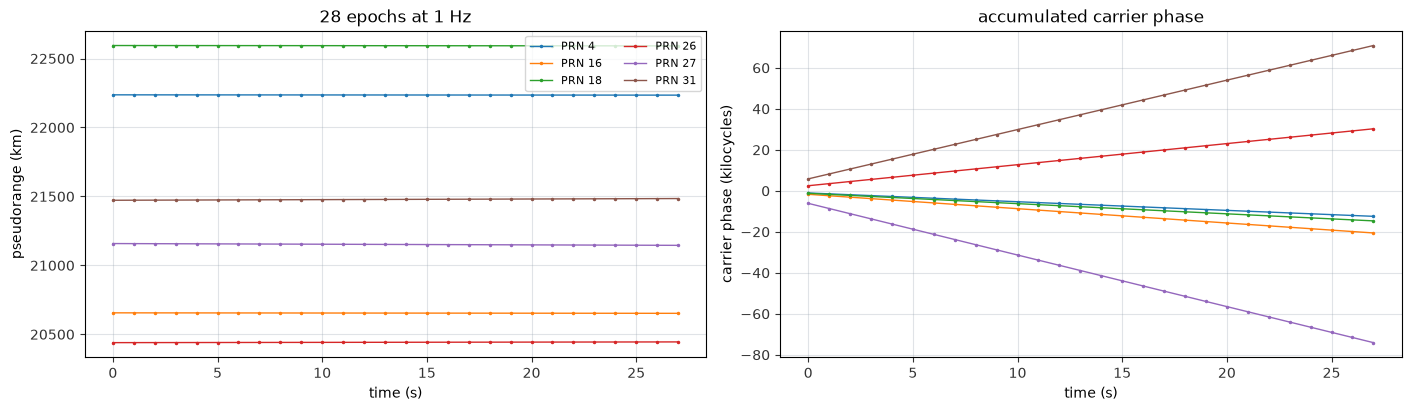

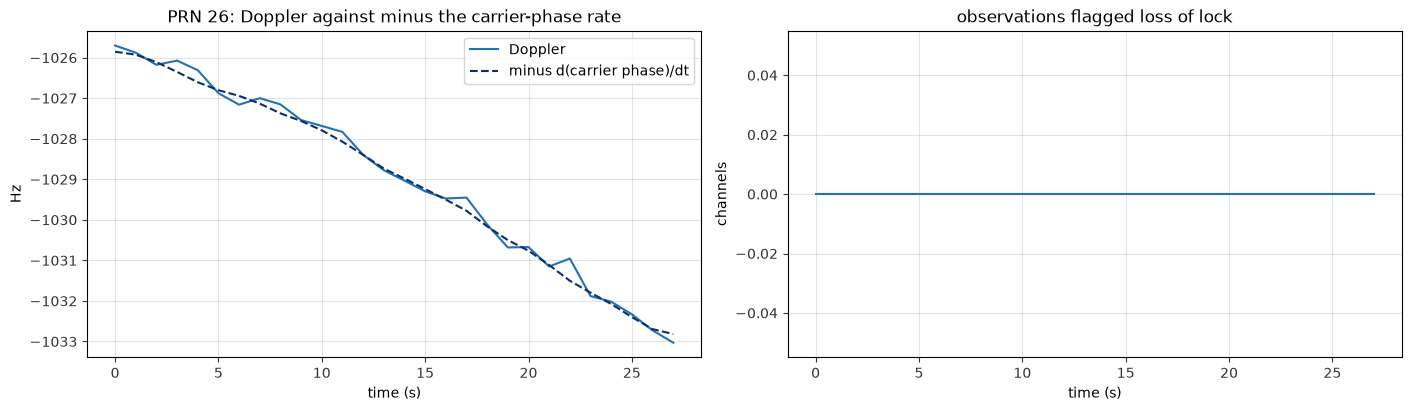

In [9]:
epochs = make_observables(tracks, lnavs)
t_rel = np.array([e.tow - epochs[0].tow for e in epochs])
prns = sorted({o.prn for e in epochs for o in e.obs})

def series(prn, field):
    return np.array([next((getattr(o, field) for o in e.obs if o.prn == prn), np.nan) for e in epochs])

fig, (ax_p, ax_l) = figure(1, 2, figsize=(14, 4))
for prn in prns:
    ax_p.plot(t_rel, series(prn, "pseudorange") / 1e3, ".-", linewidth=1, markersize=3, label=f"PRN {prn}")
    ax_l.plot(t_rel, series(prn, "carrier_phase") / 1e3, ".-", linewidth=1, markersize=3, label=f"PRN {prn}")
ax_p.set_xlabel("time (s)")
ax_p.set_ylabel("pseudorange (km)")
ax_p.set_title(f"{len(epochs)} epochs at 1 Hz")
ax_p.legend(ncol=2, fontsize=8)
ax_l.set_xlabel("time (s)")
ax_l.set_ylabel("carrier phase (kilocycles)")
ax_l.set_title("accumulated carrier phase")
plt.show()

prn = tracks[0].prn
L, D = series(prn, "carrier_phase"), series(prn, "doppler")
fig, (ax_d, ax_s) = figure(1, 2, figsize=(14, 4))
ax_d.plot(t_rel, D, color=LINES[0], label="Doppler")
ax_d.plot(t_rel, -np.gradient(L, t_rel), "--", color=LINES[2], label="minus d(carrier phase)/dt")
ax_d.set_xlabel("time (s)")
ax_d.set_ylabel("Hz")
ax_d.set_title(f"PRN {prn}: Doppler against minus the carrier-phase rate")
ax_d.legend()
ax_s.plot(t_rel, [sum(o.lli & 1 for o in e.obs) for e in epochs], color=LINES[0])
ax_s.set_xlabel("time (s)")
ax_s.set_ylabel("channels")
ax_s.set_title("observations flagged loss of lock")
plt.show()

## 6. RINEX

The observations go out as a RINEX 3.05 observation file and the decoded ephemerides as a
navigation file, the formats the positioning notebooks read back in.

In [10]:
obs_path, nav_path = out / "pyrx.obs", out / "pyrx.nav"
write_rinex_obs(obs_path, epochs)
ephs = [ln.ephemeris for ln in lnavs if ln.ephemeris is not None]
tow1 = {ln.prn: sf.tow_s for ln in lnavs for sf in ln.subframes if sf.sf_id == 1}
iono = next((ln.ionosphere for ln in lnavs if ln.ionosphere is not None), None)
write_rinex_nav(nav_path, ephs, tow1, iono)
for p in (obs_path, nav_path):
    print(f"==> {p.name}")
    print("\n".join(p.read_text().splitlines()[:25]))
    print()

==> pyrx.obs
     3.05           OBSERVATION DATA    G: GPS              RINEX VERSION / TYPE
pyrx                                    20261029 042302 UTC PGM / RUN BY / DATE
PYRX                                                        MARKER NAME
                                                            OBSERVER / AGENCY
                    pyrx                                    REC # / TYPE / VERS
                                                            ANT # / TYPE
        0.0000        0.0000        0.0000                  APPROX POSITION XYZ
        0.0000        0.0000        0.0000                  ANTENNA: DELTA H/E/N
G    4 C1C L1C D1C S1C                                      SYS / # / OBS TYPES
  2021    12    26     8    24   22.0000000     GPS         TIME OF FIRST OBS
G L1C                                                       SYS / PHASE SHIFT
                                                            END OF HEADER
> 2021 12 26 08 24 22.0000000  0  6
G04  22236668.71

## 7. Against the references

Pocket SDR processed the same recording: its Python tracker logs every channel ten times
a second and its C tracker logs the transmit time of week once a second. The first figure
compares acquisition with Pocket SDR's first logged row, which is already a tracked value:
C/N0 agrees to a fraction of a dB, while our acquisition Doppler, interpolated between
500 Hz search bins, sits tens of Hz from the tracked one. The C/N0 traces of both
trackers follow the same shape about a dB apart, the two estimators defining their noise
reference differently. The last figure is the per-second difference between our transmit
times and the C tracker's, interpolated to its time stamps; the dashed lines are the 20 ns
gate, below half a sample at 24 MHz.

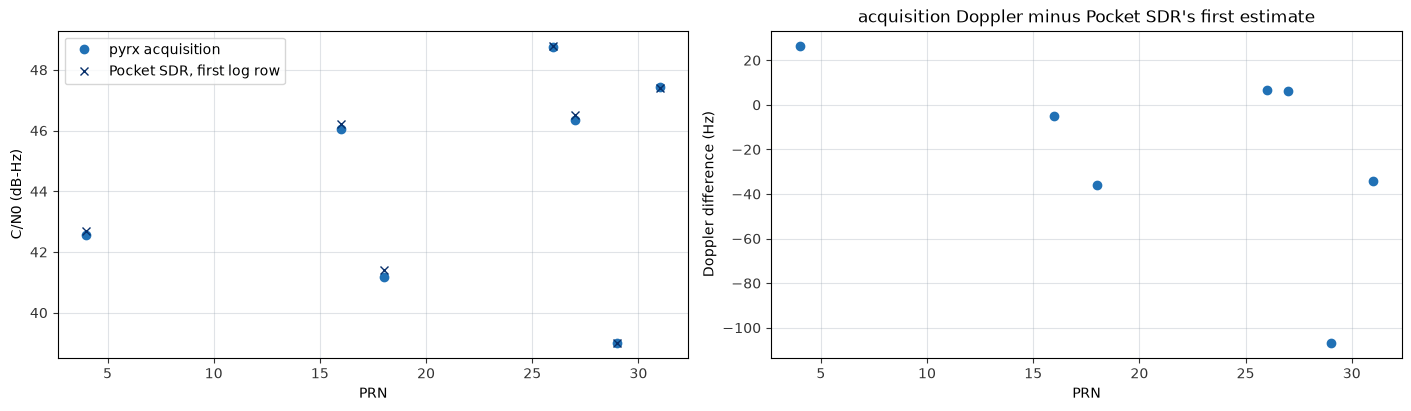

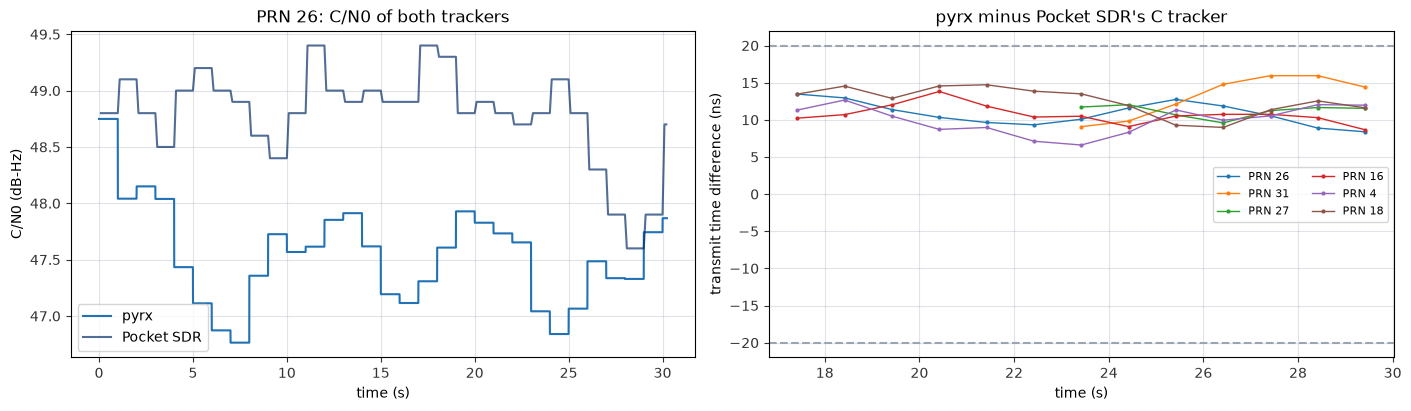

In [11]:
if src is None:
    print("synthetic data: no reference logs to compare against")
else:
    trk = read_trk_log(src.trk_log)
    ctrk = read_ctrk_log(src.ctrk_log)
    common = [r for r in detected if r.prn in trk]
    fig, (ax_c, ax_d) = figure(1, 2, figsize=(14, 4))
    ax_c.plot([r.prn for r in common], [r.cn0 for r in common], "o", color=LINES[0], label="pyrx acquisition")
    ax_c.plot([r.prn for r in common], [trk[r.prn][0, 1] for r in common], "x", color=LINES[2], label="Pocket SDR, first log row")
    ax_c.set_xlabel("PRN")
    ax_c.set_ylabel("C/N0 (dB-Hz)")
    ax_c.legend()
    ax_d.plot([r.prn for r in common], [r.doppler - trk[r.prn][0, 3] for r in common], "o", color=LINES[0])
    ax_d.set_xlabel("PRN")
    ax_d.set_ylabel("Doppler difference (Hz)")
    ax_d.set_title("acquisition Doppler minus Pocket SDR's first estimate")
    plt.show()

    fig, (ax_n, ax_t) = figure(1, 2, figsize=(14, 4))
    prn = track.prn
    ax_n.plot(rel_t, track.cn0, color=LINES[0], label="pyrx")
    ax_n.plot(trk[prn][:, 0], trk[prn][:, 1], color=LINES[2], alpha=0.7, label="Pocket SDR")
    ax_n.set_xlabel("time (s)")
    ax_n.set_ylabel("C/N0 (dB-Hz)")
    ax_n.set_title(f"PRN {prn}: C/N0 of both trackers")
    ax_n.legend()
    for tr, ln in zip(tracks, lnavs):
        if tr.prn not in ctrk or ln.stream is None:
            continue
        rows = ctrk[tr.prn]
        rows = rows[rows[:, 5] > 0]
        tc, tt = code_starts(tr), transmit_times(tr, ln)
        t = rows[:, 0]
        inside = (t >= tc[ln.stream.epoch[0]]) & (t < tc[-1])
        t = t[inside]
        k = np.searchsorted(tc, t, side="right") - 1
        ours = tt[k] + (t - tc[k]) / (tc[k + 1] - tc[k]) * 1e-3
        theirs = (rows[inside, 6] - rows[inside, 2]) * 1e-3
        ax_t.plot(t, (ours - theirs) * 1e9, ".-", linewidth=1, markersize=4, label=f"PRN {tr.prn}")
    for gate in (-20, 20):
        ax_t.axhline(gate, color=MUTED, linestyle="--")
    ax_t.set_xlabel("time (s)")
    ax_t.set_ylabel("transmit time difference (ns)")
    ax_t.set_title("pyrx minus Pocket SDR's C tracker")
    ax_t.legend(ncol=2, fontsize=8)
    plt.show()